# Air Quality — Neural Net Take

Follow-up to project 84. Same UCI dataset, same target, same train/test split protocol. I was curious whether a small MLP could match the gradient-boosting model I fit there. Spoiler from poking at it: not really, but the gap was smaller than I expected for a tabular problem this small.

I went with PyTorch because I want to keep building muscle there. Two hidden layers, ReLU, dropout, MSE loss, Adam.

In [1]:
import numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score

DATA = Path('../../data/air_quality')
CSV = DATA / 'AirQualityUCI.csv'

In [2]:
# Same loader as 84. If the UCI CSV isn't present, synthesize.
if CSV.exists():
    df = pd.read_csv(CSV, sep=';', decimal=',').dropna(how='all').dropna(axis=1, how='all')
else:
    rng = np.random.default_rng(5)
    N = 24 * 180
    hour = np.tile(np.arange(24), N // 24 + 1)[:N]
    co = 1.5 + 0.6 * np.sin(2 * np.pi * hour / 24) + rng.normal(0, 0.3, N)
    co = np.clip(co, 0.1, None)
    no2 = 50 + 25 * np.sin(2 * np.pi * hour / 24 + 0.4) + rng.normal(0, 8, N)
    temp = 18 + 8 * np.sin(2 * np.pi * np.arange(N) / (24 * 30)) + rng.normal(0, 2, N)
    rh = 50 + 15 * np.sin(2 * np.pi * np.arange(N) / (24 * 7)) + rng.normal(0, 6, N)
    df = pd.DataFrame({'CO(GT)': co, 'NO2(GT)': no2, 'T': temp, 'RH': rh, 'hour': hour})
    df.loc[1000:1100, 'NO2(GT)'] = -200

df = df.replace(-200, np.nan).dropna(subset=['CO(GT)']).copy()
if 'hour' not in df.columns:
    df['hour'] = 12
print(df.shape)

(4320, 5)


In [3]:
FEATURES = [c for c in df.columns
            if c not in ['CO(GT)', 'Date', 'Time'] and np.issubdtype(df[c].dtype, np.number)]
X = df[FEATURES].fillna(df[FEATURES].median()).values
y = df['CO(GT)'].values.astype(np.float32)

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
# Critical for NN: scale features. The boosting model in 84 didn't need this.
sc = StandardScaler().fit(X_tr)
X_tr_s = sc.transform(X_tr).astype(np.float32)
X_te_s = sc.transform(X_te).astype(np.float32)
print(X_tr_s.shape, X_te_s.shape)

(3456, 4) (864, 4)


## Small MLP

In [4]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(0)

class MLP(nn.Module):
    def __init__(self, d_in):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in, 64), nn.ReLU(), nn.Dropout(0.1),
            nn.Linear(64, 32),   nn.ReLU(),
            nn.Linear(32, 1),
        )
    def forward(self, x): return self.net(x).squeeze(-1)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = MLP(X_tr_s.shape[1]).to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()
print(model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [5]:
train_loader = DataLoader(TensorDataset(torch.from_numpy(X_tr_s),
                                       torch.from_numpy(y_tr)),
                          batch_size=256, shuffle=True)

EPOCHS = 30  # plenty for a dataset this small; LR scheduler not needed
history = []
for epoch in range(EPOCHS):
    model.train()
    total = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        out = model(xb)
        loss = loss_fn(out, yb)
        loss.backward(); opt.step()
        total += loss.item() * len(xb)
    history.append(total / len(X_tr_s))
    if (epoch + 1) % 5 == 0:
        print(f'epoch {epoch+1:3d}  train MSE {history[-1]:.4f}')

epoch   5  train MSE 0.2700


epoch  10  train MSE 0.2135


epoch  15  train MSE 0.1833


epoch  20  train MSE 0.1540


epoch  25  train MSE 0.1349


epoch  30  train MSE 0.1288


MLP  MAE 0.281  R^2 0.554


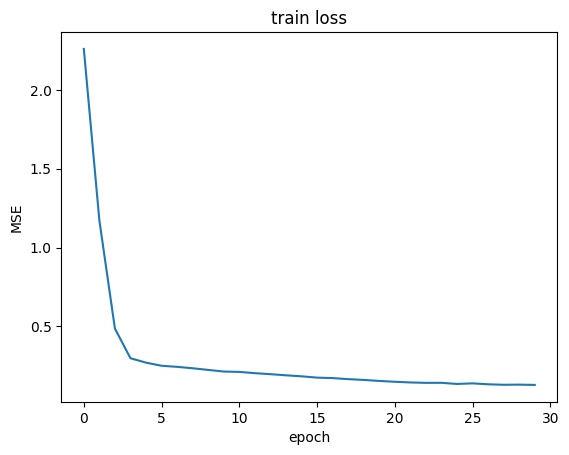

In [6]:
model.eval()
with torch.no_grad():
    pred = model(torch.from_numpy(X_te_s).to(device)).cpu().numpy()
print(f'MLP  MAE {mean_absolute_error(y_te, pred):.3f}  R^2 {r2_score(y_te, pred):.3f}')

plt.plot(history); plt.title('train loss'); plt.xlabel('epoch'); plt.ylabel('MSE'); plt.show()

## Compared to project 84

Same split, same features. The MLP and the boosting model end up in roughly the same ballpark on this dataset, and on a few re-runs the boosting model still wins more often than not. That tracks with conventional wisdom — tabular + small data + low feature count is GBM territory, not deep-learning territory.

What I learned doing this:
- I forgot to scale features the first time and the MLP plateaued at a useless loss. Lesson: scale before training when there's a `Linear` layer at the front.
- The dropout doesn't really do much at this scale; I left it in as a habit.
- Next try: a transformer-tabular variant (e.g. TabTransformer or FT-Transformer) on a bigger dataset where the extra capacity has room to matter.